In [1]:
import pandas as pd
import numpy as np

# Load the uploaded dataset
file_path = '/content/data (1).csv'
df = pd.read_csv(file_path)

# Display the shape and basic information of the dataset
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Dataset Information:")
display(df.info())


Dataset Shape: 569 rows, 33 columns

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se            

None

In [2]:
# Show the first few rows of the dataset
print("First 5 rows of the dataset:")
display(df.head())


First 5 rows of the dataset:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
# Check for missing values
missing_values = df.isnull().sum()
print("Missing values per column:")
display(missing_values[missing_values > 0])


Missing values per column:


,0
Unnamed: 32,569


### Preprocessing Steps:
1. **Drop unnecessary columns**: Remove `Unnamed: 32` (all nulls) and `id` (identifier).
2. **Encode the target label**: Convert `diagnosis` ('M' / 'B') to binary numerical format (1 / 0).

In [4]:
# 1. Drop the unnecessary columns if they exist
columns_to_drop = ['id', 'Unnamed: 32']
df_cleaned = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

# 2. Encode the target 'diagnosis' variable (M -> 1, B -> 0)
if 'diagnosis' in df_cleaned.columns:
    df_cleaned['diagnosis'] = df_cleaned['diagnosis'].map({'M': 1, 'B': 0})

print("Preprocessing complete!")
print(f"New Dataset Shape: {df_cleaned.shape[0]} rows, {df_cleaned.shape[1]} columns\n")
print("First 5 rows of preprocessed data:")
display(df_cleaned.head())

Preprocessing complete!
New Dataset Shape: 569 rows, 31 columns

First 5 rows of preprocessed data:


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Decision Tree Implementation
1. **Split the data**: Separate the target feature `diagnosis` from the independent variables.
2. **Train-Test Split**: Partition the dataset into 80% training data and 20% testing data.
3. **Model Training**: Fit a `DecisionTreeClassifier` on the training set.
4. **Evaluation**: Print the accuracy score, confusion matrix, and classification report.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Split features and target
X = df_cleaned.drop(columns=['diagnosis'])
y = df_cleaned['diagnosis']

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_classifier.fit(X_train, y_train)

# Make predictions
y_pred = dt_classifier.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9298

Confusion Matrix:
[[68  4]
 [ 4 38]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        72
           1       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



### Random Forest Implementation
1. **Model Training**: Fit a `RandomForestClassifier` on the training set using an ensemble of trees.
2. **Evaluation**: Print the accuracy score, confusion matrix, and classification report to compare with our single Decision Tree.

In [6]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_classifier.predict(X_test)

# Evaluate the model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Model Accuracy: {accuracy_rf:.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Model Accuracy: 0.9737

Confusion Matrix:
[[72  0]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



### Visualizing the Decision Tree
We will use `sklearn.tree.plot_tree` to render a high-resolution graph showing the logic of our trained `dt_classifier`.

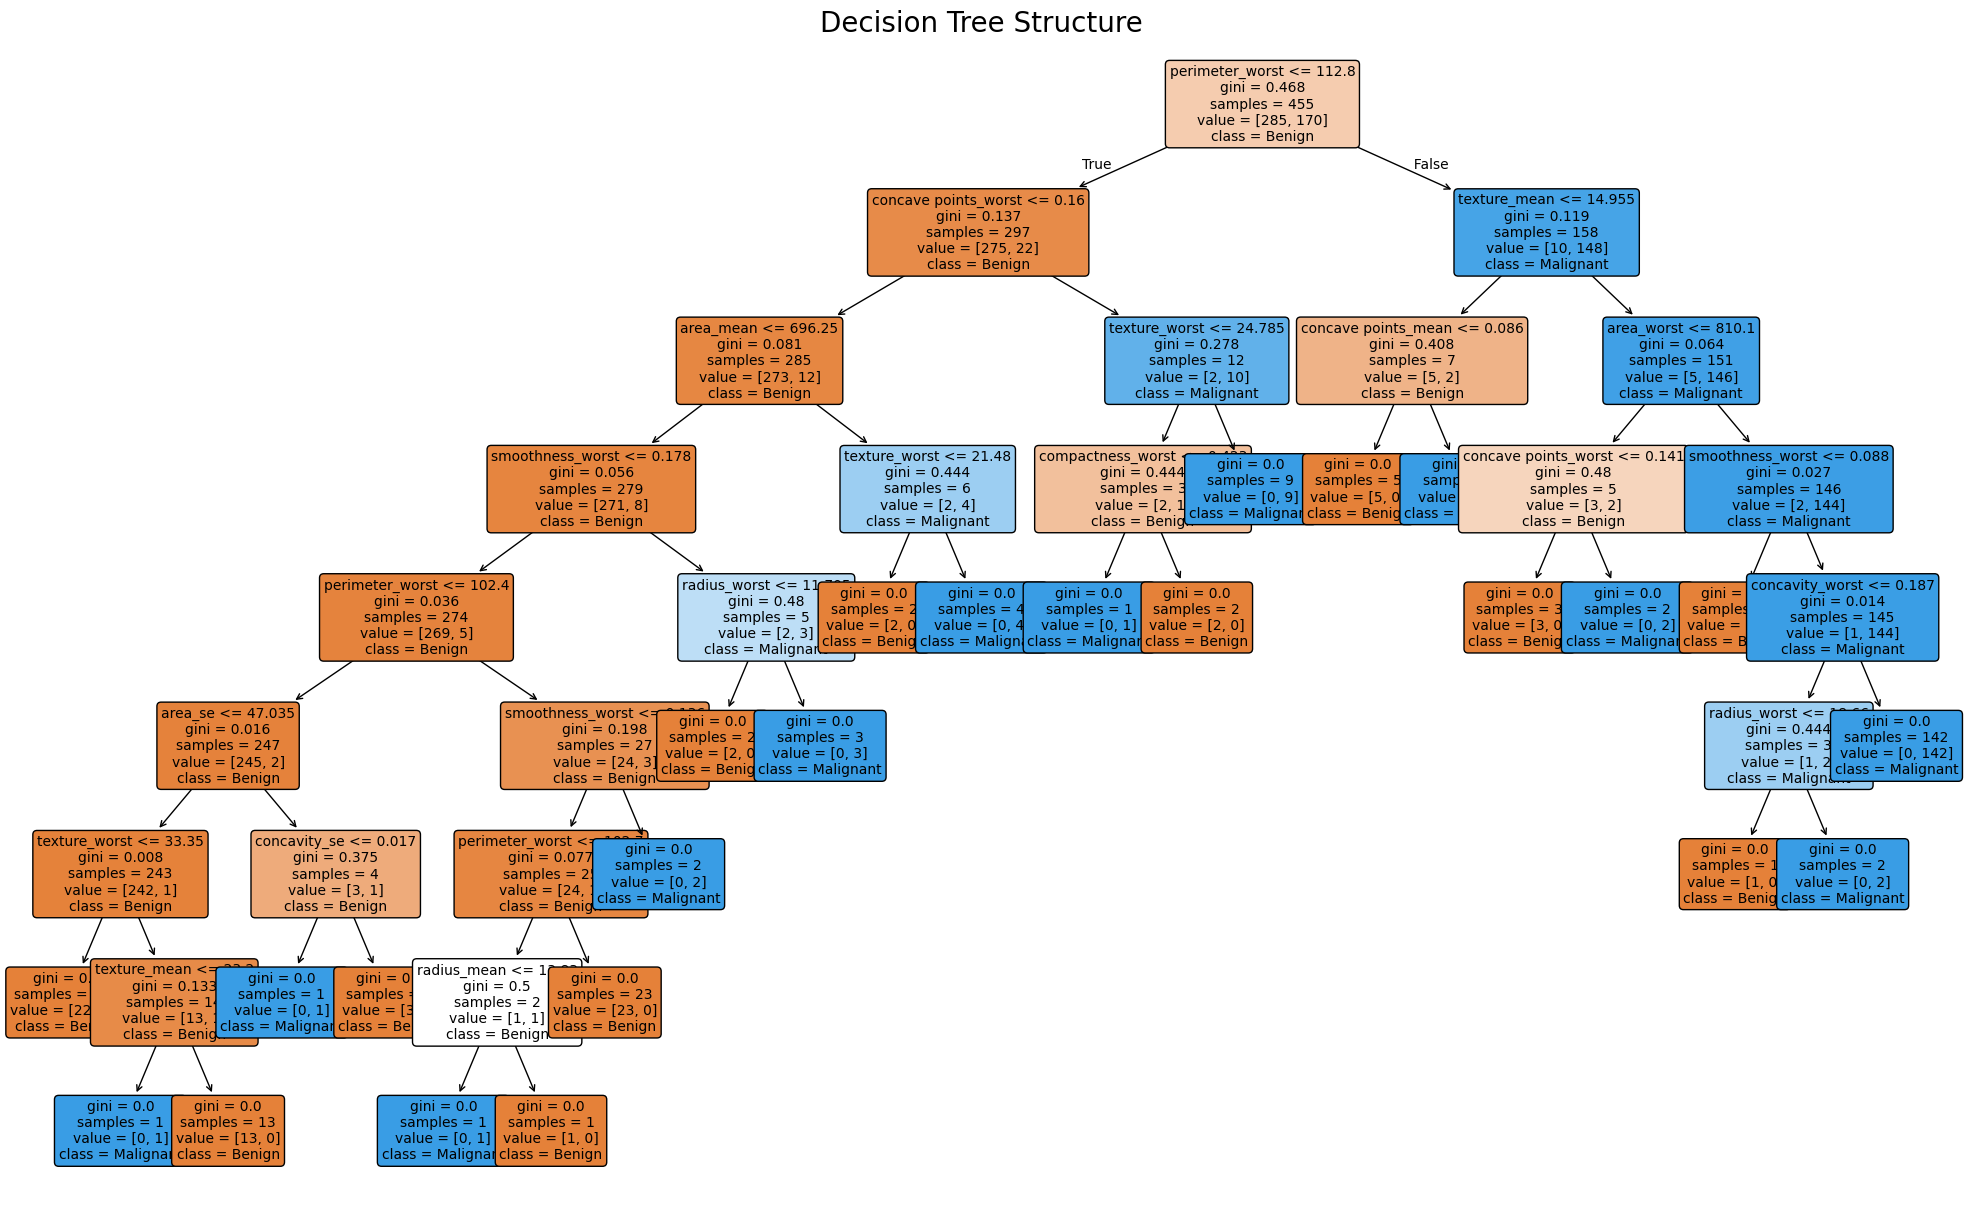

In [7]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Set a large figure size for clear visualization
plt.figure(figsize=(25, 15))

# Plot the decision tree
plot_tree(
    dt_classifier,
    feature_names=X.columns.tolist(),
    class_names=['Benign', 'Malignant'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Structure", fontsize=20)
plt.show()